# 01 · Preprocessing — Ji et al. 2020 (cutaneous SCC, 10x)

Load malignant cells, drop under-populated samples (data-derived count gap), select overdispersed genes, integrate samples with Harmony, embed, remove detached islands, annotate.

**Gate 1 (mixing + continuity)** is judged on the regenerated embedding across an integration sweep — not on a scalar.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # 'Ji2020_Skin-5'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Skin'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

# raw folder = dataset name minus any '-N' re-run suffix, prefixed 'Data_'
base = name.split('-')[0] if name.split('-')[-1].isdigit() else name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + base)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', 'Data_'+base)

dataset: Ji2020_Skin-5 | category: Skin | raw: Data_Ji2020_Skin


In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| X max %.2f (log1p of normalized counts)' % adata.X.max())
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())

Loading ../../../../../../data/unzip/CCCA/Data_Ji2020_Skin
Done.
full atlas: (48164, 32738) | X max 8.90 (log1p of normalized counts)
malignant: (10598, 32738) | samples: 10


### Sample threshold — data-derived count gap

Sort per-sample malignant counts; the largest consecutive ratio is the inflection. Threshold = geometric mean across that gap (derived per-dataset, not a copied constant).

In [4]:
n = adata.obs['sample'].value_counts()
vals = np.sort(n.values.astype(float))          # ascending
ratios = vals[1:] / vals[:-1]
gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', vals.astype(int))
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [  27   40  268  640  729 1012 1064 1130 1472 4216]
largest gap: 40 -> 268 (ratio 6.70)
derived threshold (geometric mean across gap) = 103
kept 8/10 samples -> 10531 cells


### Genes, PCA, Harmony integration, embedding

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
# Integration strength theta chosen on the embedding across a sweep (see Gate-1 cell below).
sce.pp.harmony_integrate(adata, 'sample', theta=5, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1443 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1443
2026-08-10 22:07:31,481 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-10 22:07:32,799 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-10 22:07:32,865 - harmonypy - INFO - Iteration 1 of 20
2026-08-10 22:07:35,105 - harmonypy - INFO - Iteration 2 of 20
2026-08-10 22:07:37,244 - harmonypy - INFO - Iteration 3 of 20
2026-08-10 22:07:39,389 - harmonypy - INFO - Iteration 4 of 20
2026-08-10 22:07:41,154 - harmonypy - INFO - Iteration 5 of 20
2026-08-10 22:07:42,794 - harmonypy - INFO - Converged after 5 iterations


### Gate 1 — integration sweep, judged on the embedding

Same-sample kNN fraction is a *guide*; the call is made on the regenerated sample-coloured UMAP across `theta = 0/2/5/10`. At `theta=0` patients own distinct lobes; mixing is visually clean and plateaus by `theta=5` (10x precedent: Kürten reached theta=10).

theta=0 patients own lobes; theta>=5 samples intermix on one continuous mass -> settled theta=5


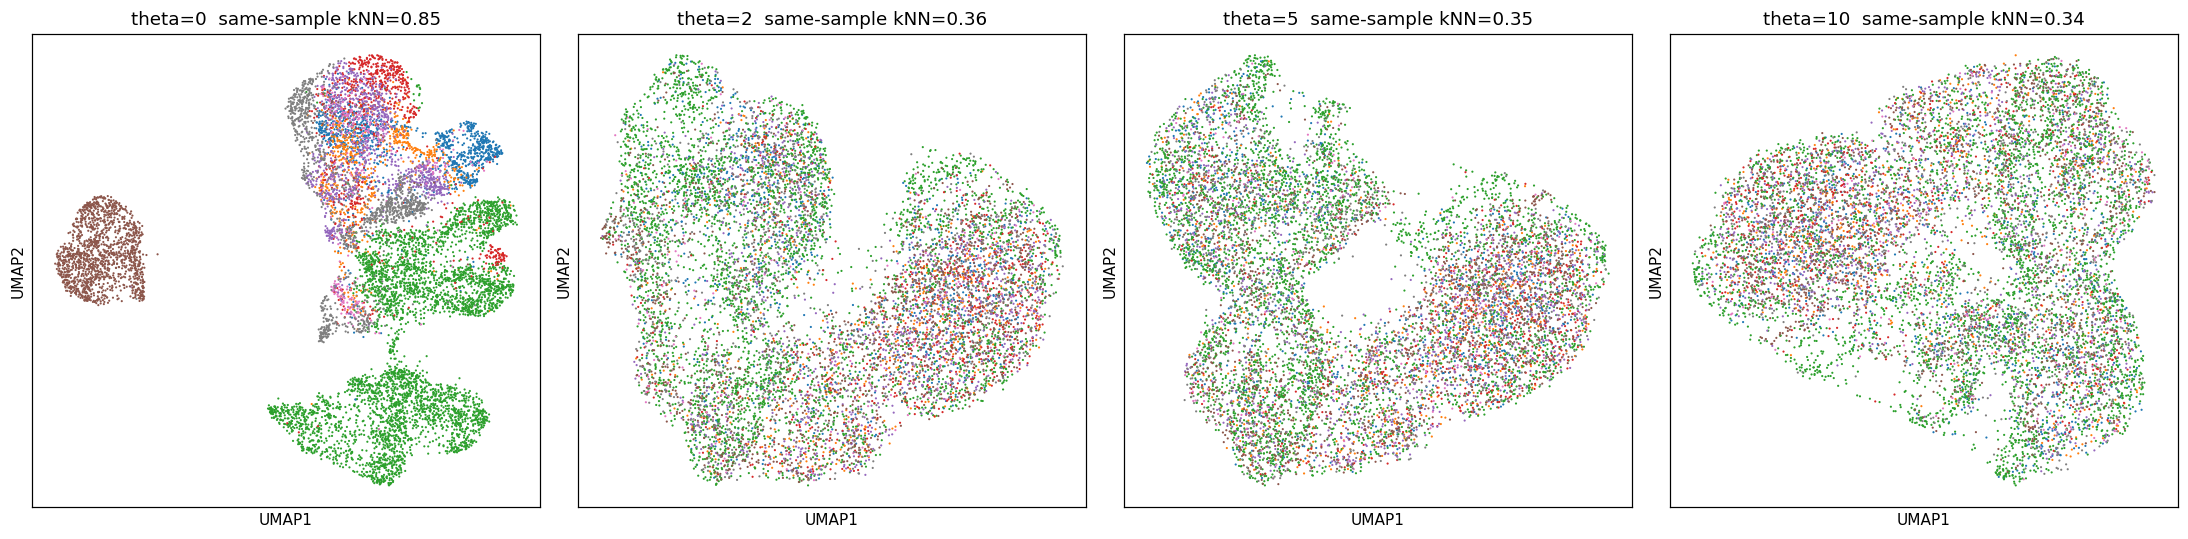

In [6]:
def same_sample_frac(ad):
    C = (ad.obsp['distances']>0).tocoo()
    s = pd.Categorical(ad.obs['sample']).codes
    return (s[C.row]==s[C.col]).mean()

fig, axs = plt.subplots(1, 4, figsize=(20,5))
for ax, th in zip(axs, [0,2,5,10]):
    b = adata.copy()
    if th==0:
        b.obsm['X_pca_harmony'] = b.obsm['X_pca'].copy()
    else:
        sce.pp.harmony_integrate(b, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sc.pp.neighbors(b, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(b, spread=1.3, random_state=SEED)
    sc.pl.umap(b, color='sample', size=8, ax=ax, show=False, legend_loc=None,
               title=f'theta={th}  same-sample kNN={same_sample_frac(b):.2f}')
plt.tight_layout(); plt.show()
print('theta=0 patients own lobes; theta>=5 samples intermix on one continuous mass -> settled theta=5')

### Island removal — UMAP radius graph, keep the largest connected component

Radius = 6× median nearest-neighbour distance; strips only disconnected specks (conservative).

In [7]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands;',
      'largest component = %.1f%%' % (100*(lab==main).mean()))
adata = adata[lab==main].copy()
print('after island removal:', adata.shape)

removed 0 cells in 0 detached islands; largest component = 100.0%
after island removal: (10531, 21042)


### Cell-cycle compartment — a confound to *characterise*, not necessarily to remove

cSCC has a large cycling compartment. The scoping decision (whether to fit the trajectory on the non-cycling cells) is re-derived in 02, from whether cell cycle confounds the embryonic modules — not copied from another dataset.

In [8]:
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('cycling fraction: %.1f%% (%d / %d)' % (100*adata.obs.cycling.mean(),
      int(adata.obs.cycling.sum()), adata.n_obs))
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())

cycling fraction: 35.4% (3729 / 10531)
lobe sizes: {'2': 3829, '1': 3531, '0': 3171}


### Subtype annotation — published Ji 2020 calls + data-derived markers

Annotation always uses both the original publication's reported subtypes and data-derived marker expression. Ji et al. 2020 provide malignant subtype calls (`cell_subtype_level1`): the differentiating/basal keratinocyte states and the tumour-specific keratinocyte (**TSK**) leading-edge / partial-EMT population.

In [9]:
# publication subtypes (Ji et al. 2020)
print('published cell_subtype_level1:')
print(adata.obs['cell_subtype_level1'].value_counts())
# data-derived marker confirmation
markers = {'Tumor_KC_Diff':['KRT1','KRT10','SBSN'],       # differentiated
           'Tumor_KC_Basal':['TP63','KRT14','COL17A1'],   # basal
           'TSK':['MMP10','PTHLH','LAMC2'],                # tumor-specific keratinocyte / leading edge
           'Tumor_KC_Cyc':['MKI67','TOP2A']}               # cycling
for sub, gs in markers.items():
    gs = [g for g in gs if g in adata.var_names]
    if gs:
        m = adata.obs['cell_subtype_level1']==sub
        if m.sum():
            mn = np.asarray(adata[m, gs].X.mean(0)).ravel()
            print(f'{sub:16s}', {g: round(float(v),2) for g,v in zip(gs, mn)})
adata.obs['celltype'] = adata.obs['cell_subtype_level1'].astype('category')

published cell_subtype_level1:
cell_subtype_level1
Keratinocyte      5688
Tumor_KC_Diff     2345
Tumor_KC_Basal    1393
Tumor_KC_Cyc       785
TSK                320
Name: count, dtype: int64
Tumor_KC_Diff    {'KRT1': 2.63, 'KRT10': 2.4, 'SBSN': 1.02}
Tumor_KC_Basal   {'TP63': 0.84, 'KRT14': 5.72, 'COL17A1': 1.71}
TSK              {'MMP10': 1.09, 'PTHLH': 1.27, 'LAMC2': 1.18}
Tumor_KC_Cyc     {'MKI67': 0.99, 'TOP2A': 0.97}


### Gate 1 — visual read on the settled embedding

8 samples intermix on one continuous manifold; no per-patient islands survive. Gate 1: mixed + continuous -> GO


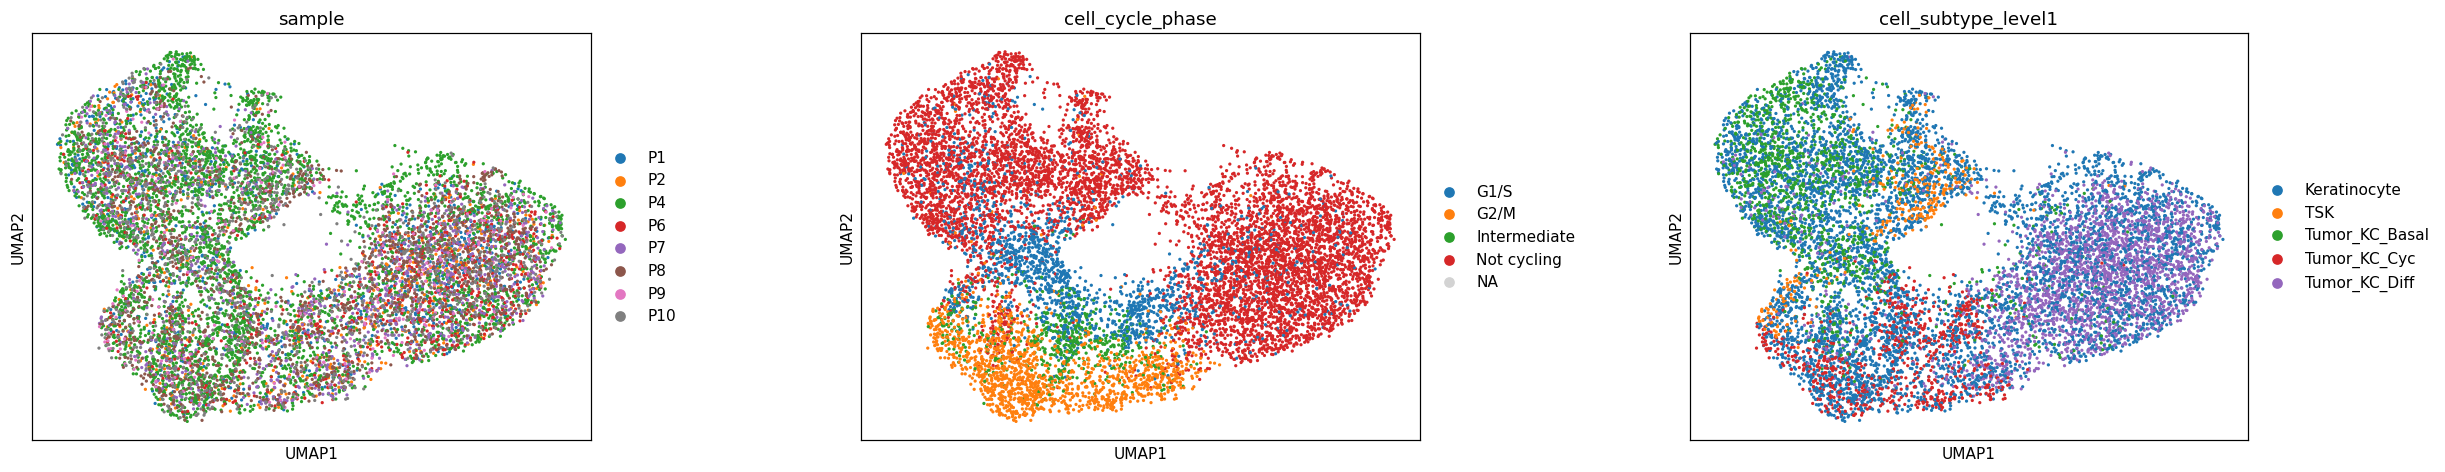

In [10]:
fig = sc.pl.umap(adata, color=['sample','cell_cycle_phase','cell_subtype_level1'],
                 size=18, wspace=.35, show=False)
plt.show()
print(f"{adata.obs['sample'].nunique()} samples intermix on one continuous manifold; "
      "no per-patient islands survive. Gate 1: mixed + continuous -> GO")

In [11]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (10531, 21042)


### `samples.pdf` — house linear style (single sample-coloured manifold)

Reference deliverable: one sample-coloured UMAP panel, `(3.5,1.5)` aspect, external legend.

saved samples.pdf


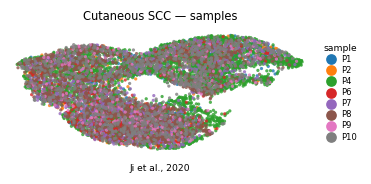

In [12]:
xy = adata.obsm['X_umap'].astype(float)
# orient the manifold's major axis horizontal (swap + y-flip; distances preserved, no rotation)
lin = np.column_stack([xy[:,1], -xy[:,0]])
plot = adata.copy(); plot.obsm['X_umap'] = lin
xlo,xhi = np.percentile(lin[:,0],[0.3,99.7]); ylo,yhi = np.percentile(lin[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=18, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Cutaneous SCC — samples', size=7.5)
ax.text(.5,-.12,'Ji et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf')